# 01 — Exploration of rail validations (Phase 3)

Inputs: `data/processed/` built by `make clean` (see `docs/data-quality.md`).
All tables come from `idf_crowding.viz.eda`; this notebook only plots them.
Entries = validations from the street (no exits, no transfers). Day types for daily
data are approximated from the weekday until the holiday calendar exists (Phase 4).

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from idf_crowding.config import load_config
from idf_crowding.viz import eda

DATA = load_config()["paths"]["data_dir"]
daily = pl.read_parquet(f"{DATA}/processed/station_daily.parquet")
profiles = pl.read_parquet(f"{DATA}/processed/station_profiles.parquet")
stations = pl.read_parquet(f"{DATA}/processed/stations.parquet")
tickets = pl.scan_parquet(f"{DATA}/interim/validations_daily_tickets.parquet")
names = dict(
    zip(stations["station_id"], stations["ref_name"].fill_null(stations["label"]), strict=False)
)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 9,
    }
)
print(
    daily.height,
    "station-days,",
    daily["station_id"].n_unique(),
    "stations,",
    daily["date"].min(),
    "to",
    daily["date"].max(),
)

2979598 station-days, 751 stations, 2015-01-01 to 2026-06-30


## 1. Network total over time
7-day centred mean of daily entries, all stations.

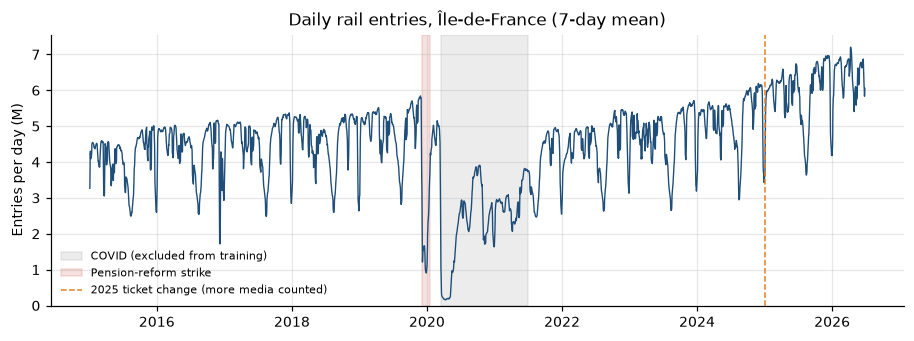

In [2]:
net = eda.network_series(daily)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(net["date"], net["total_7d"] / 1e6, lw=0.9, color="#1f4e79")
ax.axvspan(
    date(2020, 3, 17),
    date(2021, 6, 30),
    color="grey",
    alpha=0.15,
    label="COVID (excluded from training)",
)
ax.axvspan(
    date(2019, 12, 5), date(2020, 1, 20), color="#c0392b", alpha=0.15, label="Pension-reform strike"
)
ax.axvline(
    date(2025, 1, 1),
    color="#e67e22",
    ls="--",
    lw=1,
    label="2025 ticket change (more media counted)",
)
ax.set_ylabel("Entries per day (M)")
ax.set_ylim(0)
ax.legend(loc="lower left", fontsize=7, frameon=False)
ax.set_title("Daily rail entries, Île-de-France (7-day mean)")
plt.show()

## 2. Weekly pattern: how each weekday compares with Tue–Thu
Normal days only (strikes, public holidays and holiday weeks dropped by the network-ratio rule). Right panel: same without `short_passes`, the ticket group behind the 2025 break.

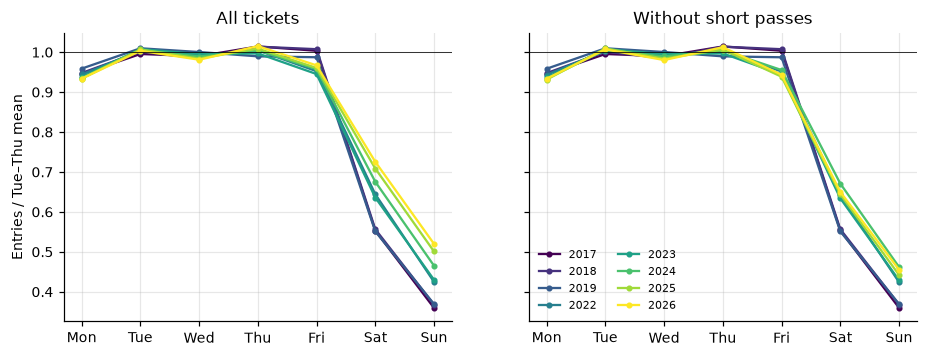

year,Mon,Tue,Wed,Thu,Fri,Sat,Sun
i32,f64,f64,f64,f64,f64,f64,f64
2017,0.945,0.996,0.99,1.014,1.004,0.553,0.36
2018,0.948,1.001,0.985,1.014,1.008,0.557,0.368
2019,0.959,1.01,1.0,0.99,0.987,0.551,0.369
2022,0.944,1.003,0.992,1.005,0.952,0.644,0.425
2023,0.938,1.008,0.995,0.997,0.945,0.636,0.43
2024,0.935,1.006,0.989,1.005,0.957,0.676,0.465
2025,0.934,1.007,0.984,1.009,0.961,0.709,0.501
2026,0.934,1.003,0.981,1.015,0.967,0.726,0.52


In [3]:
years = [2017, 2018, 2019, 2022, 2023, 2024, 2025, 2026]
wi_all = eda.weekday_index(daily, years)
wi_ex = eda.weekday_index(daily, years, totals=eda.ticket_totals(tickets, ["short_passes"]))
cmap = plt.get_cmap("viridis", len(years))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, wi, title in [(axes[0], wi_all, "All tickets"), (axes[1], wi_ex, "Without short passes")]:
    for i, y in enumerate(years):
        r = wi.filter(pl.col("year") == y).sort("weekday")
        ax.plot(eda.WEEKDAYS, r["index"], marker="o", ms=3, color=cmap(i), label=str(y))
    ax.set_title(title)
    ax.axhline(1, color="k", lw=0.5)
axes[0].set_ylabel("Entries / Tue–Thu mean")
axes[1].legend(fontsize=7, ncol=2, frameon=False)
plt.show()
wi_all.pivot(on="weekday", index="year", values="index").rename(
    {str(i + 1): d for i, d in enumerate(eda.WEEKDAYS)}
).with_columns(pl.all().exclude("year").round(3))

## 3. Yearly seasonality
Mean daily entries per month / yearly mean.

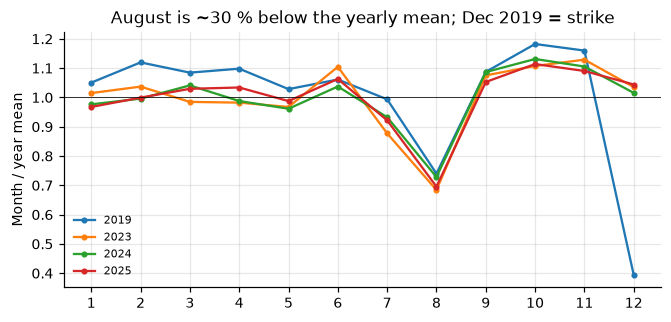

In [4]:
mi = eda.monthly_index(daily, [2019, 2023, 2024, 2025])
fig, ax = plt.subplots(figsize=(7, 3))
for y in [2019, 2023, 2024, 2025]:
    r = mi.filter(pl.col("year") == y)
    ax.plot(r["month"], r["index"], marker="o", ms=3, label=str(y))
ax.set_xticks(range(1, 13))
ax.axhline(1, color="k", lw=0.5)
ax.set_ylabel("Month / year mean")
ax.legend(frameon=False, fontsize=7)
ax.set_title("August is ~30 % below the yearly mean; Dec 2019 = strike")
plt.show()

## 4. Hour × day type at four contrasting stations (2025)
Share of the day's entries in each hour (profiles averaged over 2025 Q1–Q4).

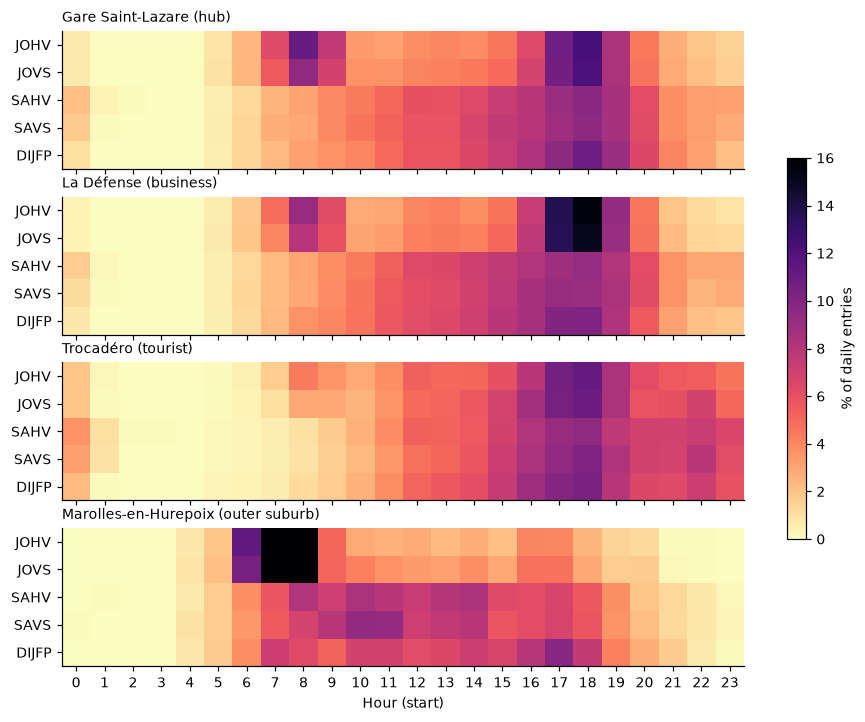

In [5]:
PERIODS_2025 = ["2025Q1", "2025Q2", "2025Q3", "2025Q4"]
showcase = {
    71370: "Gare Saint-Lazare (hub)",
    71517: "La Défense (business)",
    71285: "Trocadéro (tourist)",
    59948: "Marolles-en-Hurepoix (outer suburb)",
}
fig, axes = plt.subplots(len(showcase), 1, figsize=(10, 7.5), sharex=True)
for ax, (sid, title) in zip(axes, showcase.items(), strict=False):
    h = eda.station_heatmap(profiles, sid, PERIODS_2025)
    im = ax.imshow(h * 100, aspect="auto", cmap="magma_r", vmin=0, vmax=16)
    ax.set_yticks(range(5), eda.DAY_TYPES)
    ax.set_title(title, loc="left", fontsize=9)
    ax.grid(False)
axes[-1].set_xticks(eda.HOURS)
axes[-1].set_xlabel("Hour (start)")
fig.colorbar(im, ax=axes, shrink=0.6, label="% of daily entries")
plt.show()

## 5. Peaks are flattening
Working-day (JOHV) network profile: station profiles weighted by each station's mean daily entries.

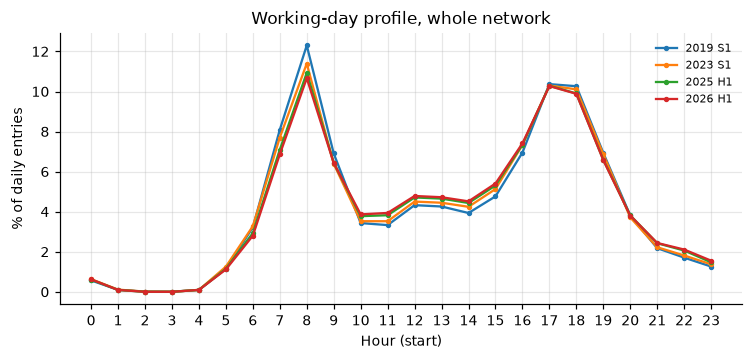

period,share 7-10h,share 17-20h,share 8-9h
str,f64,f64,f64
"""2019 S1""",0.273,0.276,0.123
"""2023 S1""",0.255,0.273,0.114
"""2025 H1""",0.245,0.268,0.109
"""2026 H1""",0.24,0.267,0.107


In [6]:
compare = {
    "2019 S1": (["2019S1"], 2019),
    "2023 S1": (["2023S1"], 2023),
    "2025 H1": (["2025Q1", "2025Q2"], 2025),
    "2026 H1": (["2026Q1", "2026Q2"], 2026),
}
fig, ax = plt.subplots(figsize=(8, 3.2))
rows = []
for label, (periods, year) in compare.items():
    m, ids = eda.profile_matrix(profiles, periods, "JOHV")
    prof = eda.weighted_profile(m, ids, eda.mean_daily(daily, year))
    ax.plot(eda.HOURS, prof * 100, marker="o", ms=2.5, label=label)
    rows.append(
        {
            "period": label,
            "share 7-10h": round(eda.peak_share(prof, range(7, 10)), 3),
            "share 17-20h": round(eda.peak_share(prof, range(17, 20)), 3),
            "share 8-9h": round(float(prof[8]), 3),
        }
    )
ax.set_xticks(eda.HOURS)
ax.set_ylabel("% of daily entries")
ax.set_xlabel("Hour (start)")
ax.legend(frameon=False, fontsize=7)
ax.set_title("Working-day profile, whole network")
plt.show()
pl.DataFrame(rows)

## 6. Station types by working-day profile
k-means on 2025 H1 JOHV hourly shares; k chosen by silhouette score.

{3: 0.401, 4: 0.31, 5: 0.316, 6: 0.28, 7: 0.278, 8: 0.273}


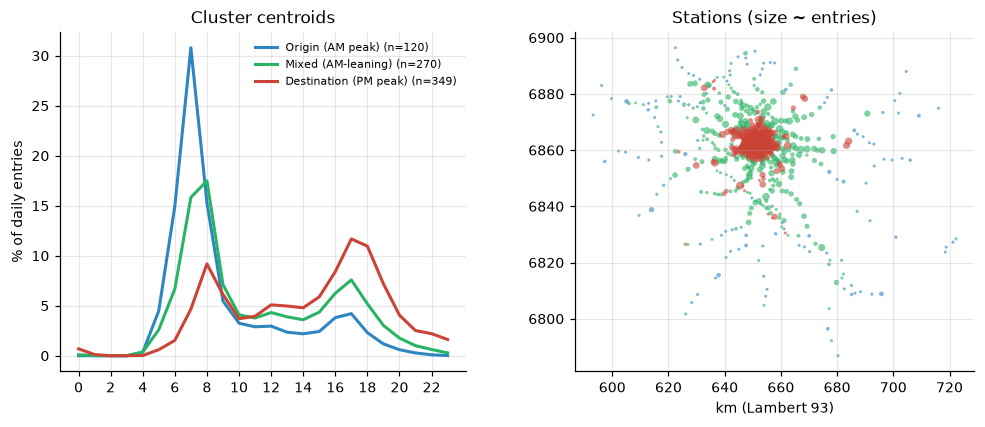

cluster,largest stations
str,str
"""Origin (AM peak)""","""Rambouillet, Mantes-la-Jolie, …"
"""Mixed (AM-leaning)""","""Noisy-le-Grand - Mont d'Est, J…"
"""Destination (PM peak)""","""Gare Saint-Lazare, La Défense,…"


In [7]:
m, ids = eda.profile_matrix(profiles, ["2025Q1", "2025Q2"], "JOHV")
print({k: round(v, 3) for k, v in eda.choose_k(m, range(3, 9)).items()})
K = 3
labels, centers = eda.cluster_profiles(m, K)
w = eda.mean_daily(daily, 2025)
names_k = ["Origin (AM peak)", "Mixed (AM-leaning)", "Destination (PM peak)"]
colors = ["#2e86c1", "#28b463", "#cb4335"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.1]})
for j in range(K):
    axes[0].plot(
        eda.HOURS,
        centers[j] * 100,
        color=colors[j],
        lw=2,
        label=f"{names_k[j]} (n={int((labels == j).sum())})",
    )
axes[0].set_xticks(eda.HOURS[::2])
axes[0].set_ylabel("% of daily entries")
axes[0].legend(frameon=False, fontsize=7)
axes[0].set_title("Cluster centroids")
xy = stations.select("station_id", "x_epsg2154", "y_epsg2154").filter(
    pl.col("x_epsg2154").is_not_null()
)
pos = {r[0]: (r[1], r[2]) for r in xy.iter_rows()}
for j in range(K):
    pts = [pos[ids[i]] for i in np.where(labels == j)[0] if ids[i] in pos]
    sz = [max(4, np.sqrt(w.get(ids[i], 0)) / 6) for i in np.where(labels == j)[0] if ids[i] in pos]
    axes[1].scatter(
        [p[0] / 1000 for p in pts],
        [p[1] / 1000 for p in pts],
        s=sz,
        color=colors[j],
        alpha=0.6,
        lw=0,
    )
axes[1].set_aspect("equal")
axes[1].set_title("Stations (size ~ entries)")
axes[1].set_xlabel("km (Lambert 93)")
plt.show()
pl.DataFrame(
    {
        "cluster": [names_k[j] for j in range(K)],
        "largest stations": [
            ", ".join(
                names.get(s, str(s))
                for s in sorted(
                    [ids[i] for i in np.where(labels == j)[0]], key=lambda s: -w.get(s, 0)
                )[:5]
            )
            for j in range(K)
        ],
    }
)

## 7. Data-quality flags over time

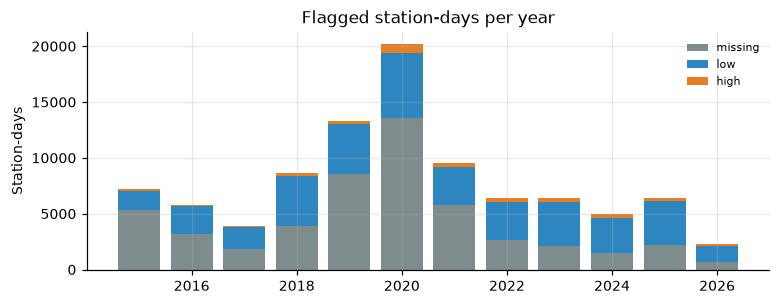

In [8]:
flags = pl.read_parquet(f"{DATA}/processed/quality/station_day_flags.parquet")
fy = (
    flags.group_by(pl.col("date").dt.year().alias("year"), "flag")
    .len()
    .pivot(on="flag", index="year", values="len")
    .sort("year")
    .fill_null(0)
)
fig, ax = plt.subplots(figsize=(8, 2.8))
bottom = np.zeros(fy.height)
for f, c in [("missing", "#7f8c8d"), ("low", "#2e86c1"), ("high", "#e67e22")]:
    ax.bar(fy["year"], fy[f], bottom=bottom, color=c, label=f)
    bottom += fy[f].to_numpy()
ax.set_ylabel("Station-days")
ax.legend(frameon=False, fontsize=7)
ax.set_title("Flagged station-days per year")
plt.show()

## Findings

1. **Level.** ~5 M entries/day before COVID, back above that from 2023; 6–7 M/day in 2025–26, partly the 2025 ticket break (more media counted). COVID (Mar 2020 – mid 2021) and the Dec 2019 strike are far outside normal variation.
2. **Weekly pattern changed after COVID.** Fridays fell from ~0.99 to ~0.95 of the Tue–Thu level, Mondays from ~0.96 to ~0.93. Weekends rose: Saturday 0.55 → 0.64–0.68, Sunday 0.37 → 0.43–0.46 (2019 → 2022–24).
3. **The 2025 break is a weekend effect.** With all tickets, Sat/Sun keep rising in 2025–26 (0.73 / 0.52); without `short_passes` they stay at the 2024 level (≈0.65 / 0.45). The break indicator must be allowed to interact with the weekday.
4. **Yearly seasonality is stable:** August ≈ −30 %, July −8 %, autumn +10 %.
5. **Peaks are flattening.** Share of working-day entries in 7–10 h: 27.3 % (2019) → 24.0 % (2026); the 8–9 h hour alone 12.3 % → 10.7 %. Hourly profiles must be taken from recent periods, not pooled from 2015.
6. **Three station types** (k-means, best silhouette at k = 3): *origin* stations in the outer ring (≈ 50 % of weekday entries between 7 and 10 h), *mixed* inner suburbs, and *destination* stations in Paris and business districts (evening peak 17–19 h). Day types change the shape a lot at origin stations, little at tourist stations.
7. **Data quality** flags concentrate on 2019–2021 (strike, COVID) and on a few small stations.

**Implications for Phases 4–5:** weekday × year interaction or a recent training window; break indicator × weekday; school holidays matter (JOVS vs JOHV differ at origin stations); station type as a feature for a global model; hourly profiles from the most recent 4 quarters.
